# Lab 3
Katherine Merrill

PHYS 434 AB

10-21-2026

## Problem 1
Simulating 100k good data points assuming gaussian fluctuations and adding bad data points at: {10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7}:

mean $\mu$ = 12 K, 
SD $\sigma$ = 0.4 K

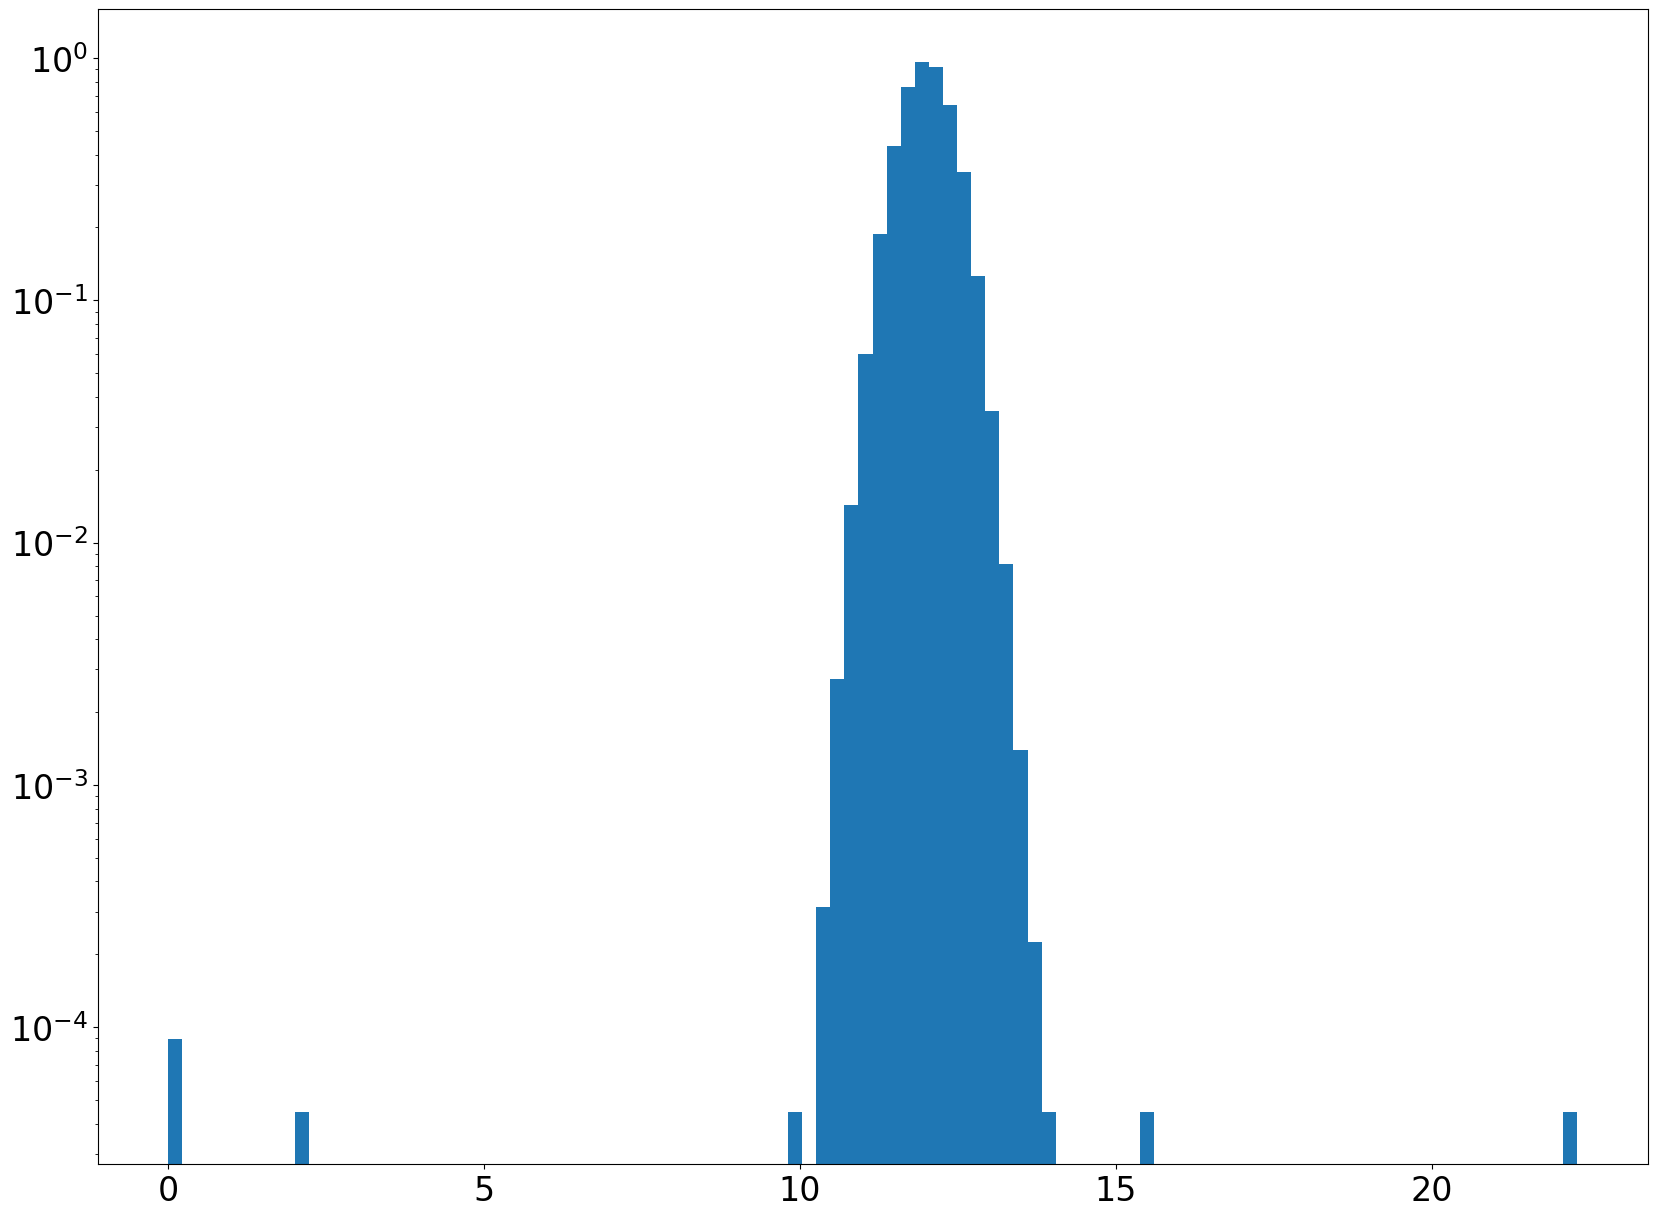

In [7]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import pandas

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

#### Part A
1) State the statistical question in words:

If a reading came from the good distribution N(12 K, 0.4 K), how likely is a reading at least this far from 12 K in either direction? 

2) Restate in math:

 z = (T − 12)/0.4, p = 2·sf(|z|).
 If we receive a reading, what is the probability that |z|< some threshold in either direction from the mean ?

3) Apply your statistical test and construct a truth table.

In [33]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])

mu=12
sigma=0.4
z=(-mu)/sigma
p=stats.norm.sf(z)
k=10

subset = d[d<k]
print (subset)

[2.1 0.  0. ]


B) How does the number of omissions, where you threw out good data, depend on the statistical threshold you chose and is it a predictable quantity?

| | True Good| True Bad |
| :---     | :---:    | ---:     |
| Test Good :)    | 100,000   | 4  |
| Test Bad :(    | 0  | 3   |

Is the table for k=10 as the statistical threshold

C) Are there mistakes of commission (bad data getting in)? If yes, are they avoidable and how do they depend on your statistical threshold?

Yes. A lower threshold means that more bad data is allowed to get in.

# Problem 2

The background distribution is a 2D gaussian with a 1 arcsecond RMS (This means $\sigma$=1 arcsecond too)

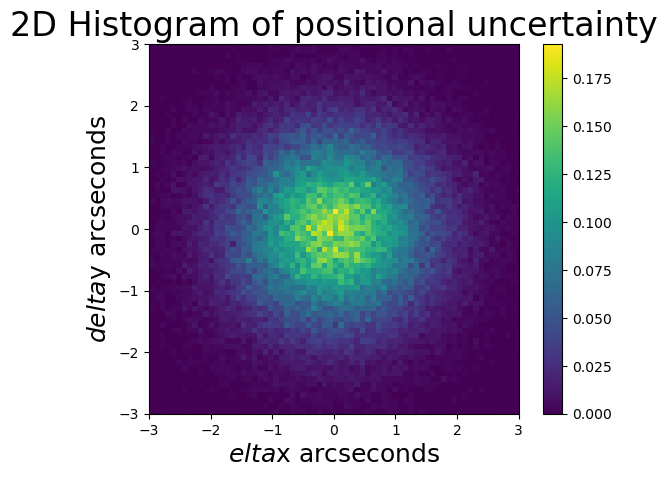

In [26]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import pandas
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel("$delta$y arcseconds", fontsize = 18)
plt.xlabel("$delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)




A1) Question in words: for a stationary star whose apparent shift is 2D Gaussian noise with 1 RMS per $\Delta y$ axis and $\Delta x$ arcseconds axis, what distance r would give a probability of a false detection of movement that is equal to the 5 sigma tail of the 2d gaussian distribution? 

Question in math:
The rayleigh distribution gives the distance r=$\sqrt{\Delta X^2+ \Delta Y^2}$ as the distance from the center (with the highest uncertainty) to the tails (with the least uncertainty). r follows a Rayleigh distribution, with tail $P(R ≥ r) = e^{−r²/2σ²}. taking the norm.sf for the 5 sigma gives2.866515718791933e-07, and taking the inverse surtvival function of that gives 5.489079776062419.

In [25]:
p=stats.norm.sf(5)
r=stats.rayleigh.isf(p)
print (p)

print(r)

2.866515718791933e-07
5.489079776062419


## part 3)

r₅ = 5.489079776062419 arcsec 

## Problem 3



3a) What is the significance of the decrease in cosmic rays that are observed over 15 days due to the Moon being in the way? 

3b) Translate the question to math:
8h night x 60 min hour x 15 days=7200 min, 
7200 min x 1 cosmic ray/min = 7200 expected counts. The expected background pdf will be a Poisson distribution since its discrete (only integer values of yes/no was a cosmic ray observed). 

In [27]:
p_value = stats.poisson.cdf(6800, 7200)
print(p_value)

1.0133280183917768e-06


The integral ill need to do will be to integrate the pdf from left to right (since we are below the expected number of cosmic ray observations). To find the pdf for each second, convolving the poisson distribution with itself will give the pdf for each second.